In [1]:
import numpy as np
import pickle

In [2]:
with open("data/data.pickle", "rb") as p:
    data = pickle.load(p)

In [3]:
np.array(data["train"][0][0]).shape

(2, 99)

In [4]:
train_x = []
test_x = []
train_y = data["train"][1]
test_y = data["test"][1]

for i in data["train"][0]:
    train_x.append(np.array(i).T.tolist())
for i in data["test"][0]:
    test_x.append(np.array(i).T.tolist())

In [5]:
from tslearn.preprocessing import TimeSeriesScalerMeanVariance
from tslearn.utils import to_time_series_dataset

/home/banhmingot45/Desktop/AsthmaticDragon/.venv/lib/python3.11/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [6]:
train_x = to_time_series_dataset(train_x)
test_x = to_time_series_dataset(test_x)

train_x = TimeSeriesScalerMeanVariance().fit_transform(train_x)
test_x = TimeSeriesScalerMeanVariance().fit_transform(test_x)

In [7]:
from tslearn.neighbors import KNeighborsTimeSeriesClassifier
from sklearn.metrics import classification_report

In [8]:
knn = KNeighborsTimeSeriesClassifier(n_neighbors=7)
knn.fit(train_x, train_y)
y_pred = knn.predict(test_x)

print(classification_report(test_y, y_pred, target_names=["normal", "box", "inhaler", "b1", "b2", "i1", "i2"]))

              precision    recall  f1-score   support

      normal       0.80      0.80      0.80         5
         box       0.40      0.40      0.40         5
     inhaler       1.00      0.40      0.57         5
          b1       0.75      0.60      0.67         5
          b2       0.44      0.80      0.57         5
          i1       0.80      0.80      0.80         5
          i2       0.60      0.60      0.60         5

    accuracy                           0.63        35
   macro avg       0.68      0.63      0.63        35
weighted avg       0.68      0.63      0.63        35



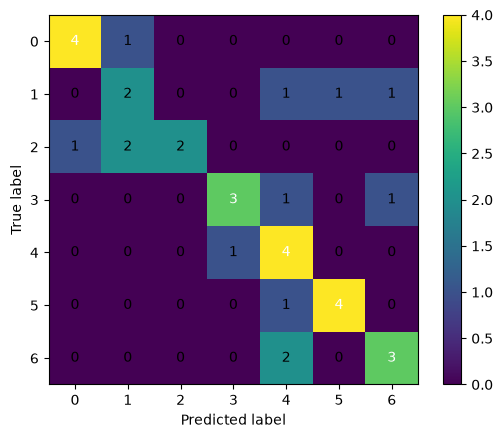

In [9]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(test_y, y_pred)
plt.imshow(cm)
plt.colorbar()
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [10]:
knn.to_pickle("final_model_release/knn.pickle")

In [11]:
from tslearn.svm import TimeSeriesSVC

In [31]:
svc = TimeSeriesSVC(C=0.67, random_state=0)
svc.fit(train_x, train_y)
y_pred = svc.predict(test_x)

print(classification_report(test_y, y_pred, target_names=["normal", "box", "inhaler", "b1", "b2", "i1", "i2"]))

/home/banhmingot45/Desktop/AsthmaticDragon/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


              precision    recall  f1-score   support

      normal       1.00      0.80      0.89         5
         box       0.67      0.40      0.50         5
     inhaler       1.00      1.00      1.00         5
          b1       0.71      1.00      0.83         5
          b2       1.00      0.40      0.57         5
          i1       0.62      1.00      0.77         5
          i2       0.83      1.00      0.91         5

    accuracy                           0.80        35
   macro avg       0.83      0.80      0.78        35
weighted avg       0.83      0.80      0.78        35



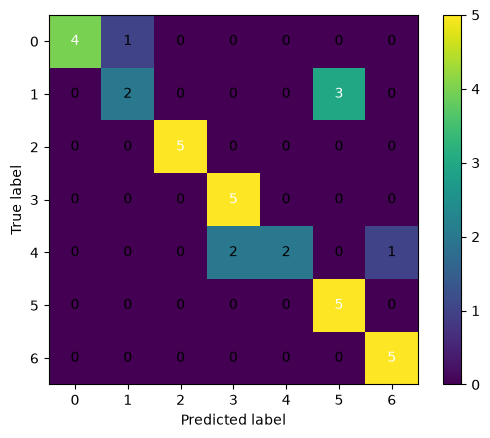

In [32]:
cm = confusion_matrix(test_y, y_pred)
plt.imshow(cm)
plt.colorbar()
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [33]:
with open("final_model_release/svc.pickle", "wb") as p:
    pickle.dump(svc, p)